# Projeto 06 — Airbnb NYC · Notebook 01: EDA, hipóteses e decisões de limpeza

**Pergunta central (enunciado):** como descobrir segmentos úteis de imóveis quando não existe uma variável-alvo que diga a qual
grupo cada anúncio pertence?

Este notebook prepara a clusterização (notebook 02):

1. formula hipóteses de negócio e inventaria as colunas;
2. audita integridade, ausentes e faixas impossíveis;
3. descreve as distribuições e as diferenças por `room_type` e `neighbourhood_group`;
4. registra cada decisão de limpeza e de features, com a evidência que a sustenta.

Todos os números vêm das células executadas. As decisões de limpeza e de features foram aprovadas no Checkpoint 1
(2026-10-20).

**Como executar** (na raiz do projeto, com o `.venv` ativado):

```bash
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb
```

## 1. Pergunta de negócio e hipóteses

Uma empresa de aluguel por temporada quer entender seu portfólio de anúncios em Nova York sem categorias de segmento predefinidas.
A **unidade de análise é o anúncio** (`id`), e não uma reserva, uma pessoa ou uma hospedagem. O dataset é um **snapshot histórico
de 2019**: não descreve o mercado atual.

Uma boa segmentação não é a que maximiza um índice. Ela precisa usar features coerentes, justificar o número de grupos, lidar com
ruído e produzir grupos que alguém consiga usar (comunicação, organização do inventário, entendimento das diferenças entre imóveis).

Origem das hipóteses:

- **H1 a H3** foram formuladas a partir do enunciado, no plano do projeto, **antes** de abrir os dados.
- **H4** e o limiar de **30 noites** da H2 foram acrescentados depois de uma auditoria rápida do arquivo (contagens e quantis),
  feita antes desta EDA detalhada.

As hipóteses orientam a investigação e não são conclusões antecipadas.

| # | Hipótese | Features que a representam | O que tornaria o grupo comercialmente útil |
|---|---|---|---|
| H1 | Imóveis inteiros com preço mais alto e estadia mínima curta têm perfil diferente dos quartos privados e compartilhados de preço baixo. | `room_type`, `price`, `minimum_nights` | Precificação e comunicação distintas para "imóvel completo" e "quarto". Só é útil se o grupo trouxer algo além do próprio `room_type` renomeado. |
| H2 | Anúncios com estadia mínima longa (≥ 30 noites) formam um perfil de média duração, com menos atividade de avaliações. | `minimum_nights`, `reviews_per_month` | Produto e operação diferentes (estadias longas, menor giro). Útil se o grupo tiver tamanho suficiente para uma ação dedicada. |
| H3 | Anfitriões com portfólio grande e alta disponibilidade declarada têm perfil de "operador", diferente do anfitrião ocasional. | `calculated_host_listings_count`, `availability_365` | Relacionamento e ferramentas para quem gerencia muitos anúncios. |
| H4 | Existe um conjunto de anúncios com pouca atividade observada (sem avaliações e/ou com disponibilidade declarada zero). | `reviews_per_month`, `availability_365` (`last_review` só descritiva) | Revisão do inventário. Disponibilidade zero **não** prova lotação nem inatividade; o grupo só sinaliza onde olhar. |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from src import config, data, plots, profiling

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
plots.apply_style()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 160
config.REPORTS_DIR.mkdir(exist_ok=True)

def log_ticks(ax, max_value, axis="x"):
    # Eixo em log1p com rótulos nas unidades originais.
    ticks = [v for v in [0, 1, 3, 10, 30, 100, 300, 1_000, 3_000, 10_000] if v <= max_value * 1.05]
    labels = [f"{t:,}".replace(",", ".") for t in ticks]
    (ax.set_xticks if axis == "x" else ax.set_yticks)(np.log1p(ticks), labels)

Python 3.11.9 | pandas 3.0.5 | numpy 2.4.6 | scikit-learn 1.9.0 | matplotlib 3.11.1


## 2. Carga, integridade e unidade de análise

In [2]:
raw = data.load_raw()
print("arquivo :", config.DATA_PATH.relative_to(config.PROJECT_ROOT))
print("SHA-256 :", data.file_sha256(config.DATA_PATH))
print("formato :", raw.shape)
raw.drop(columns=["host_name"]).head(3)

arquivo : data\AB_NYC_2019.csv
SHA-256 : e420db40ff10fcb40efc1b5b1648ee0b18a48f4e4537155cecc59fe95d18783a
formato : (48895, 16)


,id,name,host_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaT,NaN,1,365


In [3]:
near_duplicate_keys = ["host_id", "latitude", "longitude", "room_type", "price", "minimum_nights"]
integrity = pd.Series({
    "linhas": len(raw),
    "id único": raw["id"].is_unique,
    "anfitriões distintos (host_id)": raw["host_id"].nunique(),
    "linhas duplicadas (todas as colunas)": int(raw.duplicated().sum()),
    "linhas duplicadas (exceto id)": int(raw.drop(columns="id").duplicated().sum()),
    "linhas com mesmo anfitrião, coordenadas, tipo, preço e estadia mínima": int(raw.duplicated(near_duplicate_keys, keep=False).sum()),
}, name="valor")
integrity.to_frame()

,valor
linhas,48895
id único,True
anfitriões distintos (host_id),37457
linhas duplicadas (todas as colunas),0
linhas duplicadas (exceto id),0
"linhas com mesmo anfitrião, coordenadas, tipo, preço e estadia mínima",2


**Leitura.** O `id` é único e não há linhas duplicadas, nem ignorando o `id`. Só um par de anúncios do mesmo anfitrião coincide
em coordenadas, tipo, preço e estadia mínima. Isso é compatível com unidades parecidas no mesmo prédio, e não há evidência para
removê-lo. A base tem, portanto, um anúncio por linha, como o enunciado pressupõe.

### 2.1 Inventário de colunas

Uma linha por coluna do arquivo, com a família, o papel no projeto e o cuidado de interpretação. O inventário inicial seguia a
tabela de famílias de colunas do enunciado (seção 3). O papel registrado aqui é o **final**, com as decisões da seção 10 aprovadas
no Checkpoint 1. Tipo, ausentes e cardinalidade são calculados no arquivo.

In [4]:
inventory_roles = [
    # (coluna, família, papel no projeto, cuidado)
    ("id", "identificador", "chave do anúncio (unidade de análise); identifica cada linha na saída da segmentação",
     "nunca usar como número"),
    ("name", "texto livre", "fora da análise", "título do anúncio; não entra na distância"),
    ("host_id", "identificador", "só para conferir calculated_host_listings_count", "nunca usar como número contínuo"),
    ("host_name", "texto livre", "fora da análise (não exibido)", "nome de pessoa; sem valor para o perfil comercial"),
    ("neighbourhood_group", "categórica (distritos)", "comparação descritiva dos perfis; testada como representação R3",
     "se entrar como input, a comparação posterior vira tautológica"),
    ("neighbourhood", "categórica (alta cardinalidade)", "só descritiva",
     "um OneHot com uma dummy por bairro dominaria a distância"),
    ("latitude", "coordenada", "só mapas", "grau não equivale a quilômetro"),
    ("longitude", "coordenada", "só mapas", "grau não equivale a quilômetro"),
    ("room_type", "categórica (tipo de imóvel)", "feature (OneHot)", "comparar os clusters com ela depois é tautológico"),
    ("price", "numérica: perfil comercial", "feature (winsorização p99,5 + log1p); price = 0 excluído",
     "assimetria forte e valores extremos"),
    ("minimum_nights", "numérica: condição do anúncio", "feature (teto de 365 + log1p)",
     "pico em 30 noites e valores implausíveis"),
    ("number_of_reviews", "numérica: atividade", "só descritiva (redundante com reviews_per_month)",
     "não mede satisfação nem receita"),
    ("last_review", "data", "só descritiva", "não é série temporal; ausente quando não há avaliação"),
    ("reviews_per_month", "numérica: atividade", "feature (ausente = 0, winsorização p99,5, log1p)",
     "não mede satisfação nem receita"),
    ("calculated_host_listings_count", "numérica: portfólio do anfitrião", "feature (log1p, sem teto)",
     "atributo do anfitrião repetido em cada anúncio dele"),
    ("availability_365", "numérica: disponibilidade declarada", "feature (sem transformação)", "não é taxa de ocupação"),
]
inventory = pd.DataFrame(inventory_roles, columns=["column", "família", "papel no projeto", "cuidado"]).set_index("column")
assert list(inventory.index) == config.EXPECTED_COLUMNS, "o inventário precisa cobrir as 16 colunas, na ordem do arquivo"
inventory = data.quality_report(raw)[["dtype", "pct_missing", "n_unique"]].join(inventory)
inventory.to_csv(config.REPORTS_DIR / "eda_column_inventory.csv")
with pd.option_context("display.max_colwidth", None):
    display(inventory)

,dtype,pct_missing,n_unique,família,papel no projeto,cuidado
column,,,,,,
id,int64,0.00,48895,identificador,chave do anúncio (unidade de análise); identifica cada linha na saída da segmentação,nunca usar como número
name,str,0.03,47905,texto livre,fora da análise,título do anúncio; não entra na distância
host_id,int64,0.00,37457,identificador,só para conferir calculated_host_listings_count,nunca usar como número contínuo
host_name,str,0.04,11452,texto livre,fora da análise (não exibido),nome de pessoa; sem valor para o perfil comercial
neighbourhood_group,str,0.00,5,categórica (distritos),comparação descritiva dos perfis; testada como representação R3,"se entrar como input, a comparação posterior vira tautológica"
neighbourhood,str,0.00,221,categórica (alta cardinalidade),só descritiva,um OneHot com uma dummy por bairro dominaria a distância
latitude,float64,0.00,19048,coordenada,só mapas,grau não equivale a quilômetro
longitude,float64,0.00,14718,coordenada,só mapas,grau não equivale a quilômetro
room_type,str,0.00,3,categórica (tipo de imóvel),feature (OneHot),comparar os clusters com ela depois é tautológico


## 3. Qualidade: tipos, ausentes e faixas impossíveis

In [5]:
quality = data.quality_report(raw)
quality.to_csv(config.REPORTS_DIR / "eda_quality_report.csv")
quality

,dtype,n_missing,pct_missing,n_unique
column,,,,
id,int64,0,0.00,48895
name,str,16,0.03,47905
host_id,int64,0,0.00,37457
host_name,str,21,0.04,11452
neighbourhood_group,str,0,0.00,5
neighbourhood,str,0,0.00,221
latitude,float64,0,0.00,19048
longitude,float64,0,0.00,14718
room_type,str,0,0.00,3


In [6]:
no_reviews = raw["number_of_reviews"].eq(0)
structural = pd.DataFrame({
    "reviews_per_month ausente": pd.crosstab(no_reviews, raw["reviews_per_month"].isna()).loc[:, True],
    "last_review ausente": pd.crosstab(no_reviews, raw["last_review"].isna()).loc[:, True],
}).rename(index={False: "number_of_reviews > 0", True: "number_of_reviews = 0"})
structural

,reviews_per_month ausente,last_review ausente
number_of_reviews,,
number_of_reviews > 0,0,0
number_of_reviews = 0,10052,10052


**Leitura.** `reviews_per_month` e `last_review` têm 10.052 ausentes cada, e **todos** caem nos anúncios com `number_of_reviews = 0`.
É ausência estrutural: o anúncio ainda não recebeu avaliações. Por isso:

- `reviews_per_month` ausente vira **0**, a taxa observada de fato. Imputar mediana ou média inventaria atividade que não existe.
- `last_review` ausente **não** recebe data imputada. Ela só é usada de forma descritiva (seção 8).
- `name` (16 ausentes) e `host_name` (21) são texto livre, fora das features. As ausências não afetam a análise.

In [7]:
checks = data.range_checks(raw)
checks.to_csv(config.REPORTS_DIR / "eda_range_checks.csv", index=False)
checks

,rule,kind,n_rows,pct_rows
0,price <= 0,domínio,11,0.02
1,minimum_nights < 1,domínio,0,0.00
2,"availability_365 fora de [0, 365]",domínio,0,0.00
3,number_of_reviews < 0,domínio,0,0.00
4,reviews_per_month < 0,domínio,0,0.00
5,calculated_host_listings_count < 1,domínio,0,0.00
6,coordenadas fora do retângulo de NYC,domínio,0,0.00
7,reviews_per_month ausente com number_of_review...,consistência,0,0.00
8,reviews_per_month presente com number_of_revie...,consistência,0,0.00
9,last_review ausente com number_of_reviews > 0,consistência,0,0.00


In [8]:
raw.loc[raw["price"] <= 0, ["id", "room_type", "neighbourhood_group", "price", "minimum_nights",
                            "availability_365", "number_of_reviews"]]

,id,room_type,neighbourhood_group,price,minimum_nights,availability_365,number_of_reviews
23161,18750597,Private room,Brooklyn,0,4,28,1
25433,20333471,Private room,Bronx,0,2,127,55
25634,20523843,Private room,Brooklyn,0,2,0,16
25753,20608117,Private room,Brooklyn,0,2,0,12
25778,20624541,Entire home/apt,Brooklyn,0,5,73,3
25794,20639628,Private room,Brooklyn,0,1,176,93
25795,20639792,Private room,Brooklyn,0,1,232,95
25796,20639914,Private room,Brooklyn,0,1,222,95
26259,20933849,Entire home/apt,Manhattan,0,3,0,0
26841,21291569,Shared room,Brooklyn,0,30,333,2


**Leitura.**

- **Domínio:** a única violação é `price = 0`, em 11 anúncios. Preço zero não é um preço comercial válido. Alguns desses anúncios
  têm dezenas de avaliações, o que indica erro de registro e não gratuidade. **Decisão: excluir essas 11 linhas da base
  clusterizada.**
- **Consistência:** as regras entre `number_of_reviews`, `reviews_per_month` e `last_review` não têm nenhuma violação.
- **Coordenadas:** todas caem no retângulo aproximado dos cinco distritos (checagem de sanidade com limites externos).
- **Plausibilidade:** 14 anúncios exigem mais de 365 noites (até 1.250) e 239 têm preço acima de US$ 1.000 (até 10.000, incluindo
  valores como 9.999). Esses não são impossíveis, mas pedem tratamento. Eles seguem na base, e o tratamento está na seção 9.

In [9]:
listings, cleaning_log = data.clean_listings(raw)
cleaning_log.to_csv(config.REPORTS_DIR / "eda_cleaning_log.csv", index=False)
cleaning_log

,rule,n_removed,n_before,n_after
0,price < 1,11,48895,48884


Daqui em diante, a análise usa `listings`: a base sem os anúncios de preço zero.

## 4. Distribuições das variáveis comerciais

In [10]:
quantiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.995]
numeric = listings[config.NUMERIC_COLUMNS].assign(
    reviews_per_month_zero_filled=listings["reviews_per_month"].fillna(0)
)
summary = numeric.describe(percentiles=quantiles).T
summary.to_csv(config.REPORTS_DIR / "eda_numeric_summary.csv")
summary

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.5%,max
price,"48,884.00",152.76,240.17,10.00,30.00,40.00,69.00,106.00,175.00,355.00,799.00,"1,000.00","10,000.00"
minimum_nights,"48,884.00",7.03,20.51,1.00,1.00,1.00,1.00,3.00,5.00,30.00,45.00,90.00,"1,250.00"
number_of_reviews,"48,884.00",23.27,44.55,0.00,0.00,0.00,1.00,5.00,24.00,114.00,214.00,256.58,629.00
reviews_per_month,"38,833.00",1.37,1.68,0.01,0.02,0.04,0.19,0.72,2.02,4.64,7.20,8.43,58.50
calculated_host_listings_count,"48,884.00",7.14,32.96,1.00,1.00,1.00,1.00,1.00,2.00,15.00,232.00,327.00,327.00
availability_365,"48,884.00",112.78,131.63,0.00,0.00,0.00,0.00,45.00,227.00,359.00,365.00,365.00,365.00
reviews_per_month_zero_filled,"48,884.00",1.09,1.60,0.00,0.00,0.00,0.04,0.37,1.58,4.31,6.80,7.97,58.50


In [11]:
skew_columns = ["price", "minimum_nights", "number_of_reviews", "reviews_per_month_zero_filled",
                "calculated_host_listings_count", "availability_365"]
skewness = pd.DataFrame({
    "assimetria (bruta)": numeric[skew_columns].skew(),
    "assimetria (log1p)": np.log1p(numeric[skew_columns]).skew(),
})
skewness

,assimetria (bruta),assimetria (log1p)
price,19.12,0.63
minimum_nights,21.83,1.50
number_of_reviews,3.69,0.36
reviews_per_month_zero_filled,3.30,0.95
calculated_host_listings_count,7.93,3.28
availability_365,0.76,-0.20


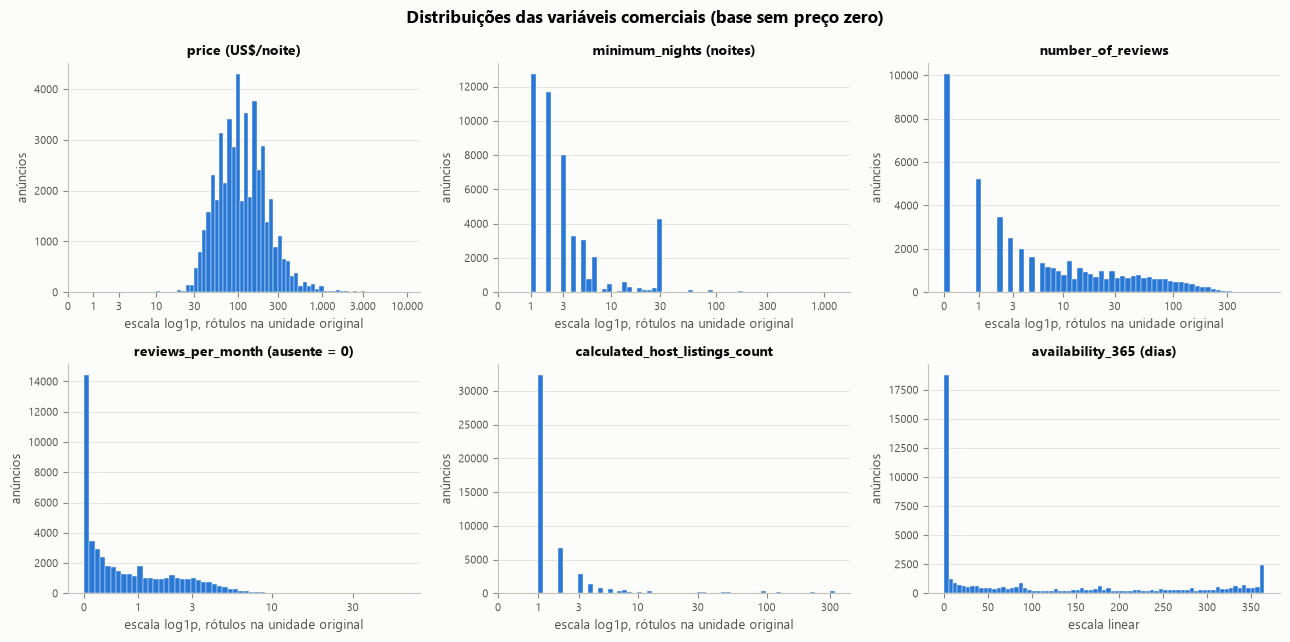

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
log_panels = [
    ("price", "price (US$/noite)"),
    ("minimum_nights", "minimum_nights (noites)"),
    ("number_of_reviews", "number_of_reviews"),
    ("reviews_per_month_zero_filled", "reviews_per_month (ausente = 0)"),
    ("calculated_host_listings_count", "calculated_host_listings_count"),
]
for ax, (column, label) in zip(axes.flat, log_panels):
    values = numeric[column]
    ax.hist(np.log1p(values), bins=60, color=plots.SERIES_COLORS[0], edgecolor=plots.SURFACE, linewidth=0.3)
    log_ticks(ax, values.max())
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("escala log1p, rótulos na unidade original")
ax = axes.flat[5]
ax.hist(numeric["availability_365"], bins=73, color=plots.SERIES_COLORS[0], edgecolor=plots.SURFACE, linewidth=0.3)
ax.set_title("availability_365 (dias)", fontsize=10)
ax.set_xlabel("escala linear")
for ax in axes.flat:
    ax.set_ylabel("anúncios")
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribuições das variáveis comerciais (base sem preço zero)", fontsize=12, fontweight="bold")
fig.tight_layout()
plots.save_figure(fig, "eda_distributions")
plt.show()

In [13]:
min_nights = listings["minimum_nights"]
pd.DataFrame({
    "anúncios": min_nights.value_counts().head(10),
    "% da base": min_nights.value_counts(normalize=True).head(10) * 100,
}).rename_axis("minimum_nights")

,anúncios,% da base
minimum_nights,,
1,12717,26.01
2,11693,23.92
3,7998,16.36
30,3758,7.69
4,3302,6.75
5,3033,6.20
7,2058,4.21
6,752,1.54
14,562,1.15


In [14]:
pd.Series({
    "% com minimum_nights <= 3": (min_nights <= 3).mean() * 100,
    "% com minimum_nights >= 30": (min_nights >= 30).mean() * 100,
    "% com availability_365 = 0": (listings["availability_365"] == 0).mean() * 100,
    "% com availability_365 >= 300": (listings["availability_365"] >= 300).mean() * 100,
    "% sem nenhuma avaliação": (listings["number_of_reviews"] == 0).mean() * 100,
    "% com availability_365 = 0 e sem avaliação": ((listings["availability_365"] == 0)
                                                    & (listings["number_of_reviews"] == 0)).mean() * 100,
}, name="valor").to_frame()

,valor
% com minimum_nights <= 3,66.30
% com minimum_nights >= 30,9.22
% com availability_365 = 0,35.86
% com availability_365 >= 300,16.70
% sem nenhuma avaliação,20.56
% com availability_365 = 0 e sem avaliação,9.91


**Leitura.**

- **Preço:** mediana de US$ 106 (p25 = 69, p75 = 175) e cauda longa até 10.000. A assimetria cai de 19,1 para 0,6 com `log1p`.
- **Estadia mínima:** dois terços dos anúncios pedem até 3 noites, mas **30 noites** é o 4º valor mais comum (3.758 anúncios).
  Ao todo, 9,2% pedem 30 noites ou mais. Esse pico é uma primeira evidência a favor de **H2**: um perfil de estadia longa pode
  existir como grupo próprio. A assimetria cai de 21,8 para 1,5 com `log1p`.
- **Avaliações:** 20,6% dos anúncios não têm nenhuma. `number_of_reviews` e `reviews_per_month` ficam bem mais simétricas
  com `log1p`.
- **Portfólio do anfitrião:** 66% dos anúncios pertencem a anfitriões com um único anúncio (seção 8). A cauda vai até 327, e a
  variável continua assimétrica mesmo após `log1p` (3,3).
- **Disponibilidade:** `availability_365` é limitada a [0, 365] e bimodal, com 35,9% de zeros e outro acúmulo perto de 365. Não
  precisa de log. Lembrete do enunciado: disponibilidade declarada **não** é taxa de ocupação. O zero pode ser calendário fechado,
  anúncio inativo ou datas já reservadas, e os dados não distinguem esses casos.

## 5. Comparação por `room_type` e `neighbourhood_group`

In [15]:
profile_room = profiling.profile_table(listings, "room_type", config.ROOM_TYPE_ORDER)
profile_room.to_csv(config.REPORTS_DIR / "eda_profile_by_room_type.csv")
profile_room

,n_listings,pct_listings,price_q1,price_median,price_q3,minimum_nights_median,pct_minimum_nights_30plus,availability_365_q1,availability_365_median,availability_365_q3,pct_availability_zero,number_of_reviews_median,reviews_per_month_median,host_listings_median
room_type,,,,,,,,,,,,,,
Entire home/apt,25407,51.97,120.00,160.00,229.00,3.00,12.42,0.00,42.00,229.00,34.93,5.00,0.35,1.00
Private room,22319,45.66,50.00,70.00,95.00,2.00,5.58,0.00,45.00,214.00,37.45,5.00,0.40,1.00
Shared room,1158,2.37,33.00,45.00,75.00,1.00,9.07,0.00,90.00,341.00,25.56,4.00,0.41,2.00


In [16]:
profile_group = profiling.profile_table(listings, "neighbourhood_group", config.NEIGHBOURHOOD_GROUP_ORDER)
profile_group.to_csv(config.REPORTS_DIR / "eda_profile_by_neighbourhood_group.csv")
profile_group

,n_listings,pct_listings,price_q1,price_median,price_q3,minimum_nights_median,pct_minimum_nights_30plus,availability_365_q1,availability_365_median,availability_365_q3,pct_availability_zero,number_of_reviews_median,reviews_per_month_median,host_listings_median
neighbourhood_group,,,,,,,,,,,,,,
Manhattan,21660,44.31,95.00,150.00,220.00,3.00,13.02,0.00,36.00,230.00,37.40,4.00,0.28,1.00
Brooklyn,20095,41.11,60.00,90.00,150.00,3.00,6.30,0.00,28.00,188.00,39.02,6.00,0.38,1.00
Queens,5666,11.59,50.00,75.00,110.00,2.00,6.37,2.00,98.00,286.00,24.14,7.00,0.76,1.00
Bronx,1090,2.23,45.00,65.00,99.00,2.00,3.49,37.00,148.00,313.75,16.24,9.00,0.87,1.00
Staten Island,373,0.76,50.00,75.00,110.00,2.00,5.09,78.00,219.00,333.00,11.26,12.00,1.00,1.00


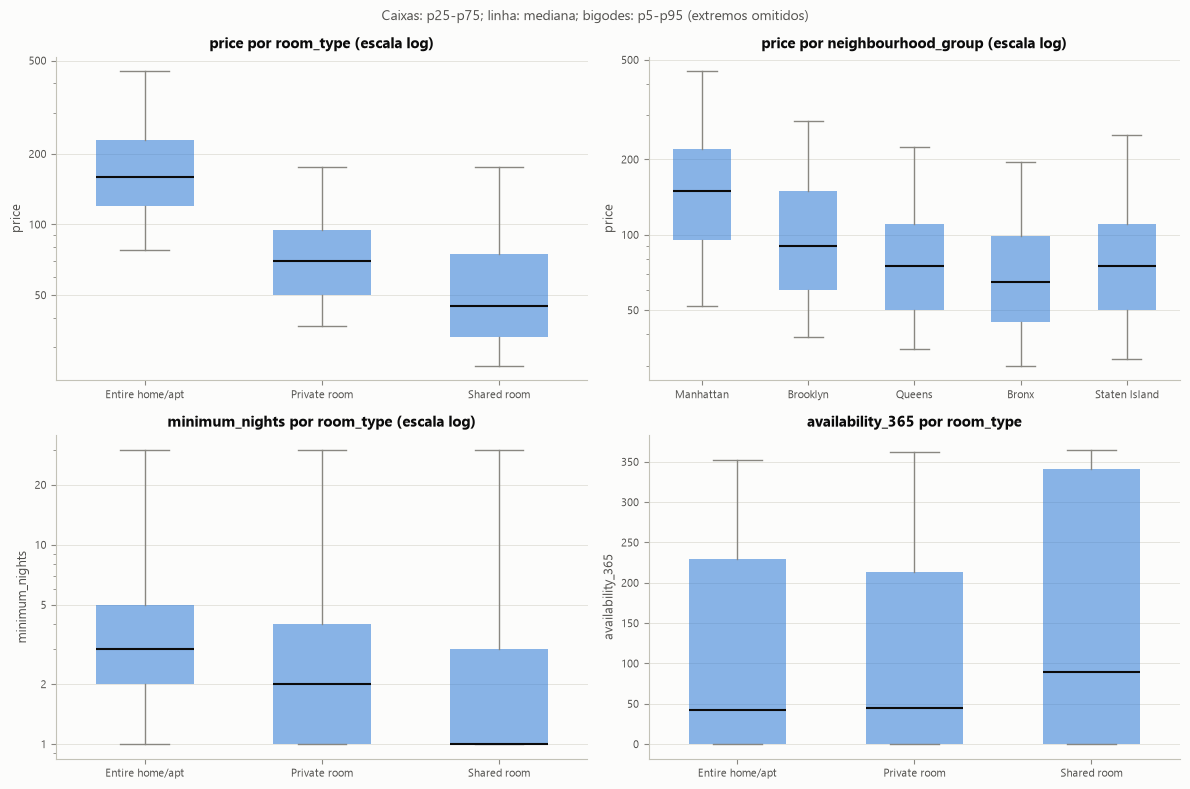

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plots.boxplot_by_group(axes[0, 0], listings, "price", "room_type", config.ROOM_TYPE_ORDER, log_scale=True)
axes[0, 0].set_title("price por room_type (escala log)")
plots.boxplot_by_group(axes[0, 1], listings, "price", "neighbourhood_group", config.NEIGHBOURHOOD_GROUP_ORDER, log_scale=True)
axes[0, 1].set_title("price por neighbourhood_group (escala log)")
plots.boxplot_by_group(axes[1, 0], listings, "minimum_nights", "room_type", config.ROOM_TYPE_ORDER, log_scale=True)
axes[1, 0].set_title("minimum_nights por room_type (escala log)")
plots.boxplot_by_group(axes[1, 1], listings, "availability_365", "room_type", config.ROOM_TYPE_ORDER)
axes[1, 1].set_title("availability_365 por room_type")
fig.suptitle("Caixas: p25-p75; linha: mediana; bigodes: p5-p95 (extremos omitidos)", fontsize=10, color=plots.INK_SECONDARY)
fig.tight_layout()
plots.save_figure(fig, "eda_boxplots_by_category")
plt.show()

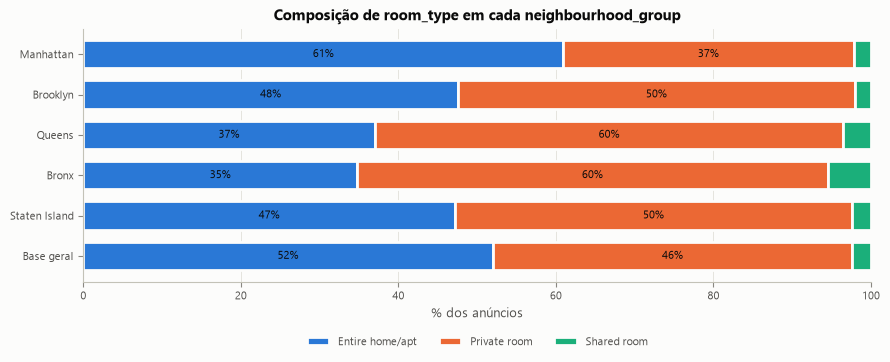

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Manhattan,60.93,36.85,2.22
Brooklyn,47.56,50.39,2.05
Queens,36.99,59.51,3.49
Bronx,34.77,59.72,5.50
Staten Island,47.18,50.40,2.41
Base geral,51.97,45.66,2.37


In [18]:
room_by_group = profiling.composition_table(
    listings, "neighbourhood_group", "room_type", config.ROOM_TYPE_ORDER, config.NEIGHBOURHOOD_GROUP_ORDER
)
fig, ax = plt.subplots(figsize=(9, 3.8))
plots.stacked_share_bars(ax, room_by_group)
ax.set_title("Composição de room_type em cada neighbourhood_group")
fig.tight_layout()
plots.save_figure(fig, "eda_room_type_by_group")
plt.show()
room_by_group

**Leitura.**

- **`room_type` separa preço com nitidez:** a mediana é USD 160 para imóveis inteiros, contra 70 para quartos privados e 45 para
  compartilhados. O intervalo interquartil dos imóveis inteiros (USD 120–229) não encosta no dos quartos privados (50–95). Já
  quartos privados e compartilhados se sobrepõem (33–75). Imóveis inteiros também pedem estadias mais longas: mediana de 3 noites
  e 12,4% com 30 ou mais, contra 2 noites e 5,6% nos quartos privados. Isso sustenta **H1**, mas com um alerta: se `room_type`
  entrar na clusterização, comparar os clusters com `room_type` depois será tautológico, e não uma validação independente.
- **`availability_365` quase não muda com o tipo de imóvel** (mediana de 42 e 45 dias nos dois tipos principais). A
  disponibilidade traz uma informação que `room_type` não tem.
- **`neighbourhood_group`:**
  - Manhattan tem a maior mediana de preço (USD 150) e a maior fatia de imóveis inteiros (61%). Em Queens e no Bronx, cerca de 60%
    são quartos privados.
  - Fora de Manhattan e Brooklyn, a disponibilidade declarada mediana é bem maior (Bronx 148 dias, Staten Island 219, contra 36 e
    28), e a mediana de avaliações por mês também (0,87 e 1,00, contra 0,28 e 0,38). É uma associação descritiva, não uma
    explicação causal.
  - Os cinco distritos têm os três tipos de imóvel: distrito não equivale a tipo de imóvel.

## 6. Concentração geográfica

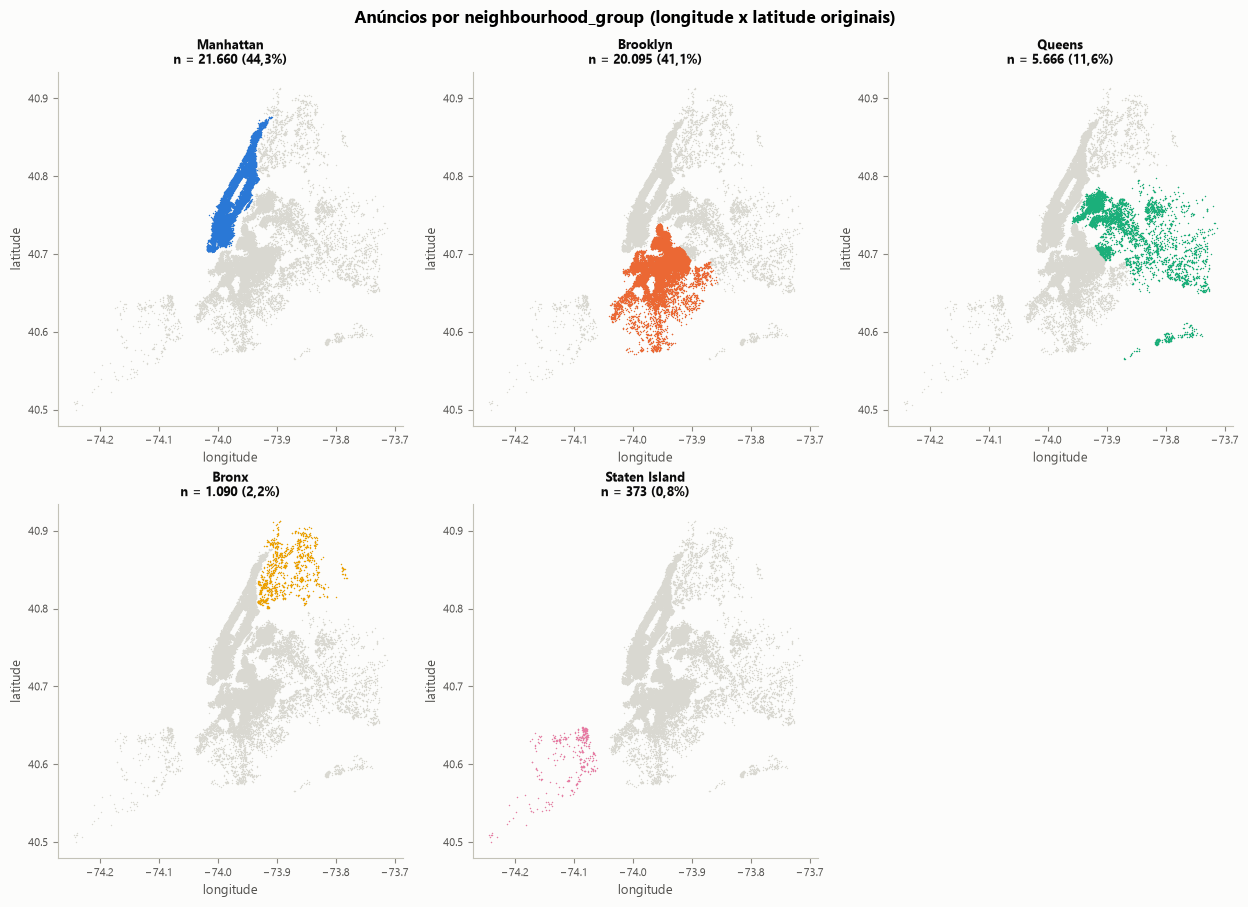

In [19]:
fig = plots.map_small_multiples(listings, "neighbourhood_group", config.NEIGHBOURHOOD_GROUP_ORDER, ncols=3)
fig.suptitle("Anúncios por neighbourhood_group (longitude x latitude originais)", fontsize=12, fontweight="bold", y=1.02)
plots.save_figure(fig, "eda_map_neighbourhood_group")
plt.show()

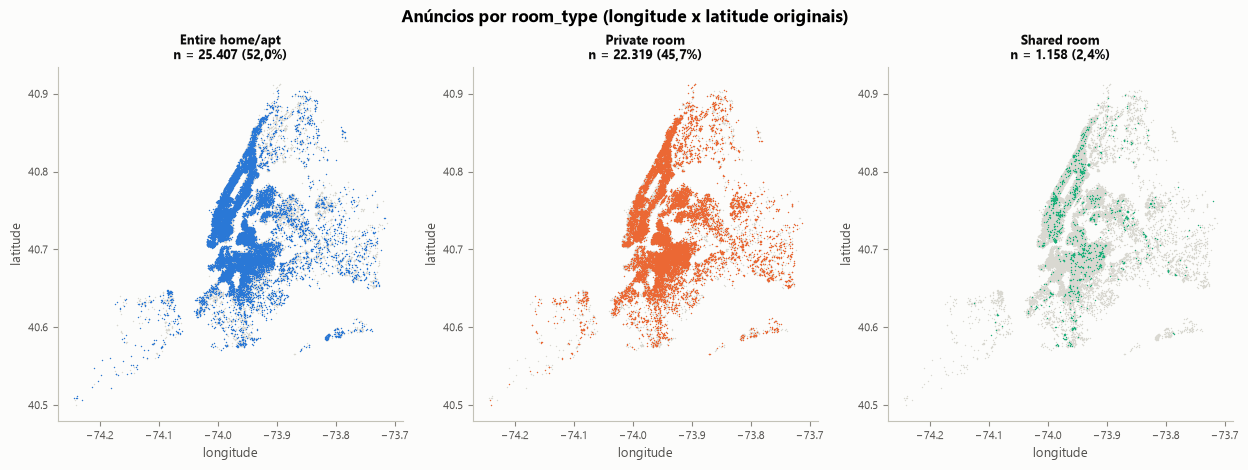

In [20]:
fig = plots.map_small_multiples(listings, "room_type", config.ROOM_TYPE_ORDER, ncols=3)
fig.suptitle("Anúncios por room_type (longitude x latitude originais)", fontsize=12, fontweight="bold", y=1.04)
plots.save_figure(fig, "eda_map_room_type")
plt.show()

In [21]:
neighbourhood_counts = listings["neighbourhood"].value_counts()
km_per_degree_lat = 111.32
km_per_degree_lon = km_per_degree_lat * np.cos(np.deg2rad(plots.NYC_MEAN_LATITUDE))
pd.Series({
    "% em Manhattan + Brooklyn": listings["neighbourhood_group"].isin(["Manhattan", "Brooklyn"]).mean() * 100,
    "bairros (neighbourhood) distintos": neighbourhood_counts.size,
    "% nos 10 bairros com mais anúncios": neighbourhood_counts.head(10).sum() / len(listings) * 100,
    "bairros com menos de 10 anúncios": int((neighbourhood_counts < 10).sum()),
    "km por grau de latitude (aprox.)": km_per_degree_lat,
    "km por grau de longitude em NYC (aprox.)": km_per_degree_lon,
}, name="valor").to_frame()

,valor
% em Manhattan + Brooklyn,85.42
bairros (neighbourhood) distintos,221.00
% nos 10 bairros com mais anúncios,47.95
bairros com menos de 10 anúncios,54.00
km por grau de latitude (aprox.),111.32
km por grau de longitude em NYC (aprox.),84.36


**Leitura.**

- **Concentração:** 85% dos anúncios estão em Manhattan e Brooklyn, e os 10 maiores bairros concentram 48% da base. A fatia
  de quartos privados é maior fora de Manhattan (cerca de 60% em Queens e no Bronx, contra 37% em Manhattan), mas os três tipos
  aparecem em toda a cidade.
  Localização e perfil comercial se relacionam, sem se confundir: **bairro não é perfil**.
- **`latitude`/`longitude`:** ficam **fora** das features de clusterização e são usadas só nos mapas. Em graus, 1 unidade de
  longitude vale cerca de 84 km e 1 de latitude cerca de 111 km, então a distância Euclidiana em graus distorce. Além disso,
  coordenadas tenderiam a produzir recortes geográficos em vez de perfis comerciais.
- **`neighbourhood`:** tem 221 categorias, 54 delas com menos de 10 anúncios. Um OneHot criaria 221 dummies esparsas que
  dominariam a distância. A coluna fica fora das features e é usada só de forma descritiva.

## 7. Relações entre as variáveis

In [22]:
transformed = pd.DataFrame({
    "log_price": np.log1p(listings["price"]),
    "log_minimum_nights": np.log1p(listings["minimum_nights"]),
    "log_number_of_reviews": np.log1p(listings["number_of_reviews"]),
    "log_reviews_per_month": np.log1p(listings["reviews_per_month"].fillna(0)),
    "log_host_listings": np.log1p(listings["calculated_host_listings_count"]),
    "availability_365": listings["availability_365"],
})
spearman = transformed.corr(method="spearman")
spearman

,log_price,log_minimum_nights,log_number_of_reviews,log_reviews_per_month,log_host_listings,availability_365
log_price,1.00,0.10,-0.05,-0.06,-0.11,0.09
log_minimum_nights,0.10,1.00,-0.17,-0.25,0.06,0.08
log_number_of_reviews,-0.05,-0.17,1.00,0.85,0.06,0.24
log_reviews_per_month,-0.06,-0.25,0.85,1.00,0.10,0.30
log_host_listings,-0.11,0.06,0.06,0.10,1.00,0.41
availability_365,0.09,0.08,0.24,0.30,0.41,1.00


**Leitura** (Spearman, que não depende do log):

- `number_of_reviews` e `reviews_per_month` medem quase a mesma coisa (ρ = 0,85). Usar as duas dobraria o peso da "atividade de
  avaliações" na distância. **Decisão (aprovada no Checkpoint 1):** manter só `reviews_per_month`, que é uma taxa e depende menos da idade do anúncio do que
  o total acumulado.
- Portfólio do anfitrião e disponibilidade declarada se associam moderadamente (ρ = 0,41), coerente com **H3**.
- Preço quase não se ordena junto com as demais variáveis (|ρ| ≤ 0,11). Ele traz informação própria para a distância.

## 8. Atividade (`last_review`) e portfólio do anfitrião

In [23]:
reference_date = listings["last_review"].max()
reviewed = listings["last_review"].notna()
print("data de referência (último last_review):", reference_date.date())
print(f"% dos anúncios avaliados cuja última avaliação é de 2019: {(listings.loc[reviewed, 'last_review'].dt.year == 2019).mean():.1%}")
listings.loc[reviewed, "last_review"].dt.year.value_counts().sort_index().rename("anúncios").to_frame().T

data de referência (último last_review): 2019-07-08
% dos anúncios avaliados cuja última avaliação é de 2019: 64.9%


last_review,2011,2012,2013,2014,2015,2016,2017,2018,2019
anúncios,7,25,48,199,1393,2707,3204,6048,25202


In [24]:
rows_per_host = raw.groupby("host_id")["id"].transform("size")
hosts = listings.drop_duplicates("host_id")
pd.Series({
    "% de linhas em que calculated_host_listings_count = nº de linhas do host_id no arquivo":
        (rows_per_host == raw["calculated_host_listings_count"]).mean() * 100,
    "% dos anfitriões com 1 anúncio": (hosts["calculated_host_listings_count"] == 1).mean() * 100,
    "% dos anúncios cujo anfitrião tem 1 anúncio": (listings["calculated_host_listings_count"] == 1).mean() * 100,
    "% dos anúncios cujo anfitrião tem 10+ anúncios": (listings["calculated_host_listings_count"] >= 10).mean() * 100,
    "maior portfólio (anúncios de um host_id)": int(listings["calculated_host_listings_count"].max()),
}, name="valor").to_frame()

,valor
% de linhas em que calculated_host_listings_count = nº de linhas do host_id no arquivo,100.00
% dos anfitriões com 1 anúncio,86.24
% dos anúncios cujo anfitrião tem 1 anúncio,66.08
% dos anúncios cujo anfitrião tem 10+ anúncios,6.50
maior portfólio (anúncios de um host_id),327.00


**Leitura.**

- **`last_review`:** não é uma série temporal, só a data da última avaliação. Ela fica fora das features por três razões:
  - não existe para 20,6% dos anúncios;
  - transformá-la em "dias desde a última avaliação" exigiria escolher uma data de referência (o snapshot termina em 2019-07-08);
  - a atividade já entra por `reviews_per_month`.
- **`calculated_host_listings_count`:** é um atributo do **anfitrião**, repetido em cada anúncio dele, e confere exatamente com o
  número de linhas do `host_id` no arquivo. 86% dos anfitriões têm um único anúncio, mas quem tem 10 ou mais responde por 6,5%
  dos anúncios. Quem tem 327 anúncios contribui com 327 linhas, então grandes operadores pesam mais na clusterização. Isso é coerente com a unidade de análise (anúncio), mas precisa estar no texto: a segmentação é **de
  anúncios**, não de anfitriões.
- **`host_id`:** nunca entra como número.

## 9. Tratamento de extremos (aprovado no Checkpoint 1)

O `log1p` reduz a assimetria, mas alguns valores continuam isolados (ex.: preço de 9.999 ou 10.000 e `minimum_nights` de 1.250).
Na distância Euclidiana, um ponto muito afastado puxa centróides e pode virar um cluster minúsculo. O tratamento aprovado
trata cada variável assim:

- **`price` e `reviews_per_month`:** winsorização superior no **percentil 99,5**, com o limite aprendido na base clusterizada e
  guardado no pipeline. Os mesmos limites valem depois para dados novos.
- **`minimum_nights`:** teto fixo de **365 noites**. Exigir mais de um ano não descreve uma condição de estadia plausível.
- **`calculated_host_listings_count`:** **sem teto**. O máximo (327) é um portfólio real, que confere com o arquivo.

Os perfis de negócio continuam usando os **valores originais**. O tratamento só existe no espaço de distância.

In [25]:
caps = listings[["price"]].assign(reviews_per_month=listings["reviews_per_month"].fillna(0)).quantile(config.WINSOR_QUANTILE)
treated = {
    "price": listings["price"].clip(upper=caps["price"]),
    "minimum_nights": listings["minimum_nights"].clip(upper=config.MINIMUM_NIGHTS_CAP),
    "reviews_per_month": listings["reviews_per_month"].fillna(0).clip(upper=caps["reviews_per_month"]),
}
original = {
    "price": listings["price"],
    "minimum_nights": listings["minimum_nights"],
    "reviews_per_month": listings["reviews_per_month"].fillna(0),
}

def max_abs_z(values):
    logged = np.log1p(values)
    return ((logged - logged.mean()) / logged.std()).abs().max()

extremes = pd.DataFrame({
    "limite superior": [caps["price"], config.MINIMUM_NIGHTS_CAP, caps["reviews_per_month"]],
    "linhas afetadas": [int((original[c] > treated[c]).sum()) for c in original],
    "max |z| só log1p": [max_abs_z(original[c]) for c in original],
    "max |z| log1p + limite": [max_abs_z(treated[c]) for c in original],
}, index=list(original))
print("para comparação, o p99,5 de minimum_nights seria:", listings["minimum_nights"].quantile(config.WINSOR_QUANTILE))
extremes

para comparação, o p99,5 de minimum_nights seria: 90.0


,limite superior,linhas afetadas,max |z| só log1p,max |z| log1p + limite
price,"1,000.00",239,6.47,3.45
minimum_nights,365.00,14,6.47,5.07
reviews_per_month,7.97,244,6.13,2.88


**Leitura.** Os limites afetam menos de 0,6% das linhas em cada variável:

- **`price`:** o limite p99,5 é US$ 1.000 (239 anúncios), e o maior |z| no espaço log cai de 6,5 para 3,5.
- **`reviews_per_month`:** o limite p99,5 é 7,97 (244 anúncios), e o maior |z| cai de 6,1 para 2,9.
- **`minimum_nights`:** o teto de 365 afeta 14 anúncios, e o maior |z| cai de 6,5 para 5,1. A cauda de estadias longas continua
  visível, o que é desejável para testar **H2**.

## 10. Decisões de limpeza e de features (aprovadas no Checkpoint 1)

| Decisão | Evidência | Status |
|---|---|---|
| Excluir anúncios com `price = 0` | 11 linhas; preço zero não é preço comercial válido | aplicada (`src/data.py`) |
| `reviews_per_month` ausente → 0 | 10.052 ausentes, 100% em anúncios sem avaliação | aprovada |
| `log1p` em `price`, `minimum_nights`, `reviews_per_month`, `calculated_host_listings_count` | assimetria bruta entre 3 e 22, bem menor após `log1p` | aprovada |
| Winsorização p99,5 em `price` e `reviews_per_month`; teto de 365 em `minimum_nights` | maior \|z\| de 6,1–6,5 para 2,9–5,1, com menos de 0,6% das linhas afetadas | aprovada |
| `availability_365` sem transformação | limitada a [0, 365], assimetria 0,76 | aprovada |
| `room_type` com OneHot (3 dummies) | separa preço com nitidez (H1); poucas categorias | aprovada |
| Fora das features: `id`, `host_id`, `name`, `host_name` | identificadores e texto livre | aplicada |
| Fora das features: `neighbourhood` | 221 categorias, 54 com menos de 10 anúncios | aprovada |
| Fora das features: `latitude`, `longitude` | distância em graus distorce e gera recortes geográficos; só mapas | aprovada |
| Fora das features: `number_of_reviews` | redundante com `reviews_per_month` (ρ = 0,85) | aprovada |
| Fora das features: `last_review` | 20,6% ausente; a atividade já entra por `reviews_per_month` | aprovada |
| `neighbourhood_group` fora da representação principal | usada para comparar perfis e testada como representação alternativa (R3) no notebook 02 | aprovada |

**Conjunto de features aprovado para a representação principal (R2):** 5 numéricas (`price`, `minimum_nights`,
`availability_365`, `reviews_per_month`, `calculated_host_listings_count`) + 1 categórica (`room_type`, OneHot). Isso cumpre a
regra de pelo menos duas numéricas e uma categórica. O escalonamento (com ou sem `StandardScaler`) é justamente o experimento
controlado do notebook 02.

**Descobertas que definiram decisões** (o plano deixava essas escolhas em aberto):

1. **Estadia mínima:** `minimum_nights = 30` é um pico próprio (3.758 anúncios). O tratamento de extremos passou a ser um teto
   em 365, e não a winsorização em p99,5, que cortaria em 90 e apagaria parte das estadias longas.
2. **Medida de atividade:** `number_of_reviews` e `reviews_per_month` são redundantes (ρ = 0,85). A representação ficou só com
   `reviews_per_month`.
3. **Portfólio do anfitrião:** `calculated_host_listings_count` ficou **sem teto**, porque o máximo (327) confere com o número de
   linhas do anfitrião no arquivo e é um portfólio real.
4. **Hipóteses:** a H4 e o limiar de 30 noites da H2 vieram da auditoria rápida (seção 1).

**Decisões do plano que a EDA confirmou:**

- imputação de `reviews_per_month` com 0 (ausência 100% estrutural);
- exclusão de `price = 0` (11 linhas);
- exclusão de `neighbourhood` (221 categorias, 54 com menos de 10 anúncios).